# 02. Grouped model evaluation

Evaluates Bi/Cr/Fe by experimental series, with C01 and C02 stored separately. This notebook calls functions from `train_models.py`. Windows and channels from the same series are never split between train and test. Sample independence and shared measurement sessions still need to be checked against the laboratory records.

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Image

cwd = Path.cwd().resolve()
BASE_DIR = next((p for p in [cwd, *cwd.parents] if (p / "src" / "dataset_config.py").exists()), None)
if BASE_DIR is None:
    raise RuntimeError("Open this notebook from the project directory or notebooks subdirectory")
if str(BASE_DIR / "src") not in sys.path:
    sys.path.insert(0, str(BASE_DIR / "src"))
import pandas as pd
from dataset_config import FIGURES_DIR, METRICS_DIR
print(BASE_DIR)

thin-film-noise-analysis


In [2]:
from train_models import (load_dataset, prepare_training_data, evaluate_models,
                          analyze_clusters, fit_final_model, analyze_comparison_films,
                          save_feature_plots)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)
df = load_dataset()
display(df.head())

,gamma,energy,jd1,jd2,record_index,sample_start,file,material,material_name,experiment_id,...,sampling_rate_hz,analysis_role,used_for_training,irradiated,control_mode,measurement_type,sample_length,overlap_mode,log_energy,electrode_distance_mm
0,0.398660,1.571536e-09,2.453598e+06,2.453598e+06,1,0,BI202C01,BI,Bismuth (Bi),BI202,...,1.731449,baseline,True,<NA>,unknown,unknown,128,2,-8.803676,NaN
1,-0.175839,3.100287e-09,2.453598e+06,2.453598e+06,1,64,BI202C01,BI,Bismuth (Bi),BI202,...,1.731449,baseline,True,<NA>,unknown,unknown,128,2,-8.508598,NaN
2,-0.094906,1.338760e-09,2.453598e+06,2.453598e+06,1,128,BI202C01,BI,Bismuth (Bi),BI202,...,1.731449,baseline,True,<NA>,unknown,unknown,128,2,-8.873297,NaN
3,-0.136083,1.224634e-09,2.453598e+06,2.453598e+06,1,192,BI202C01,BI,Bismuth (Bi),BI202,...,1.731449,baseline,True,<NA>,unknown,unknown,128,2,-8.911994,NaN
4,-0.094538,1.233776e-09,2.453598e+06,2.453598e+06,1,256,BI202C01,BI,Bismuth (Bi),BI202,...,1.731449,baseline,True,<NA>,unknown,unknown,128,2,-8.908764,NaN


In [3]:
df_train = prepare_training_data(df)
display(df_train.groupby(["material", "experiment_id", "channel"]).size().rename("n_windows").to_frame())

n_windows
material experiment_id channel           
BI       BI202         C01          32187
                       C02          32187
         BI304         C01          94551
                       C02          94551
CR       CR202         C01          32187
                       C02          32187
         CR304         C01          94551
                       C02          94551
FE       FE104         C01          94551
                       C02          94551
         FE202         C01          32187
                       C02          32187

## Grouped evaluation

Scaling is fitted inside each fold. The MLP does not use an internal random split for early stopping. If a fold is missing any class, the run stops instead of reporting a misleading score.


Grouped evaluation:
model  fold  accuracy  balanced_accuracy
  KNN     1    0.4155             0.3245
  MLP     1    0.4129             0.3225
  KNN     2    0.4619             0.3736
  MLP     2    0.6890             0.5141


,model,fold,accuracy,balanced_accuracy
0,KNN,1,0.415529,0.324543
1,MLP,1,0.412881,0.322501
2,KNN,2,0.461919,0.373618
3,MLP,2,0.688998,0.514124


,fold,partition,experiment_id
0,1,train,BI202
1,1,train,CR202
2,1,train,FE104
3,1,test,BI304
4,1,test,CR304
5,1,test,FE202
6,2,train,BI304
7,2,train,CR304
8,2,train,FE202
9,2,test,BI202


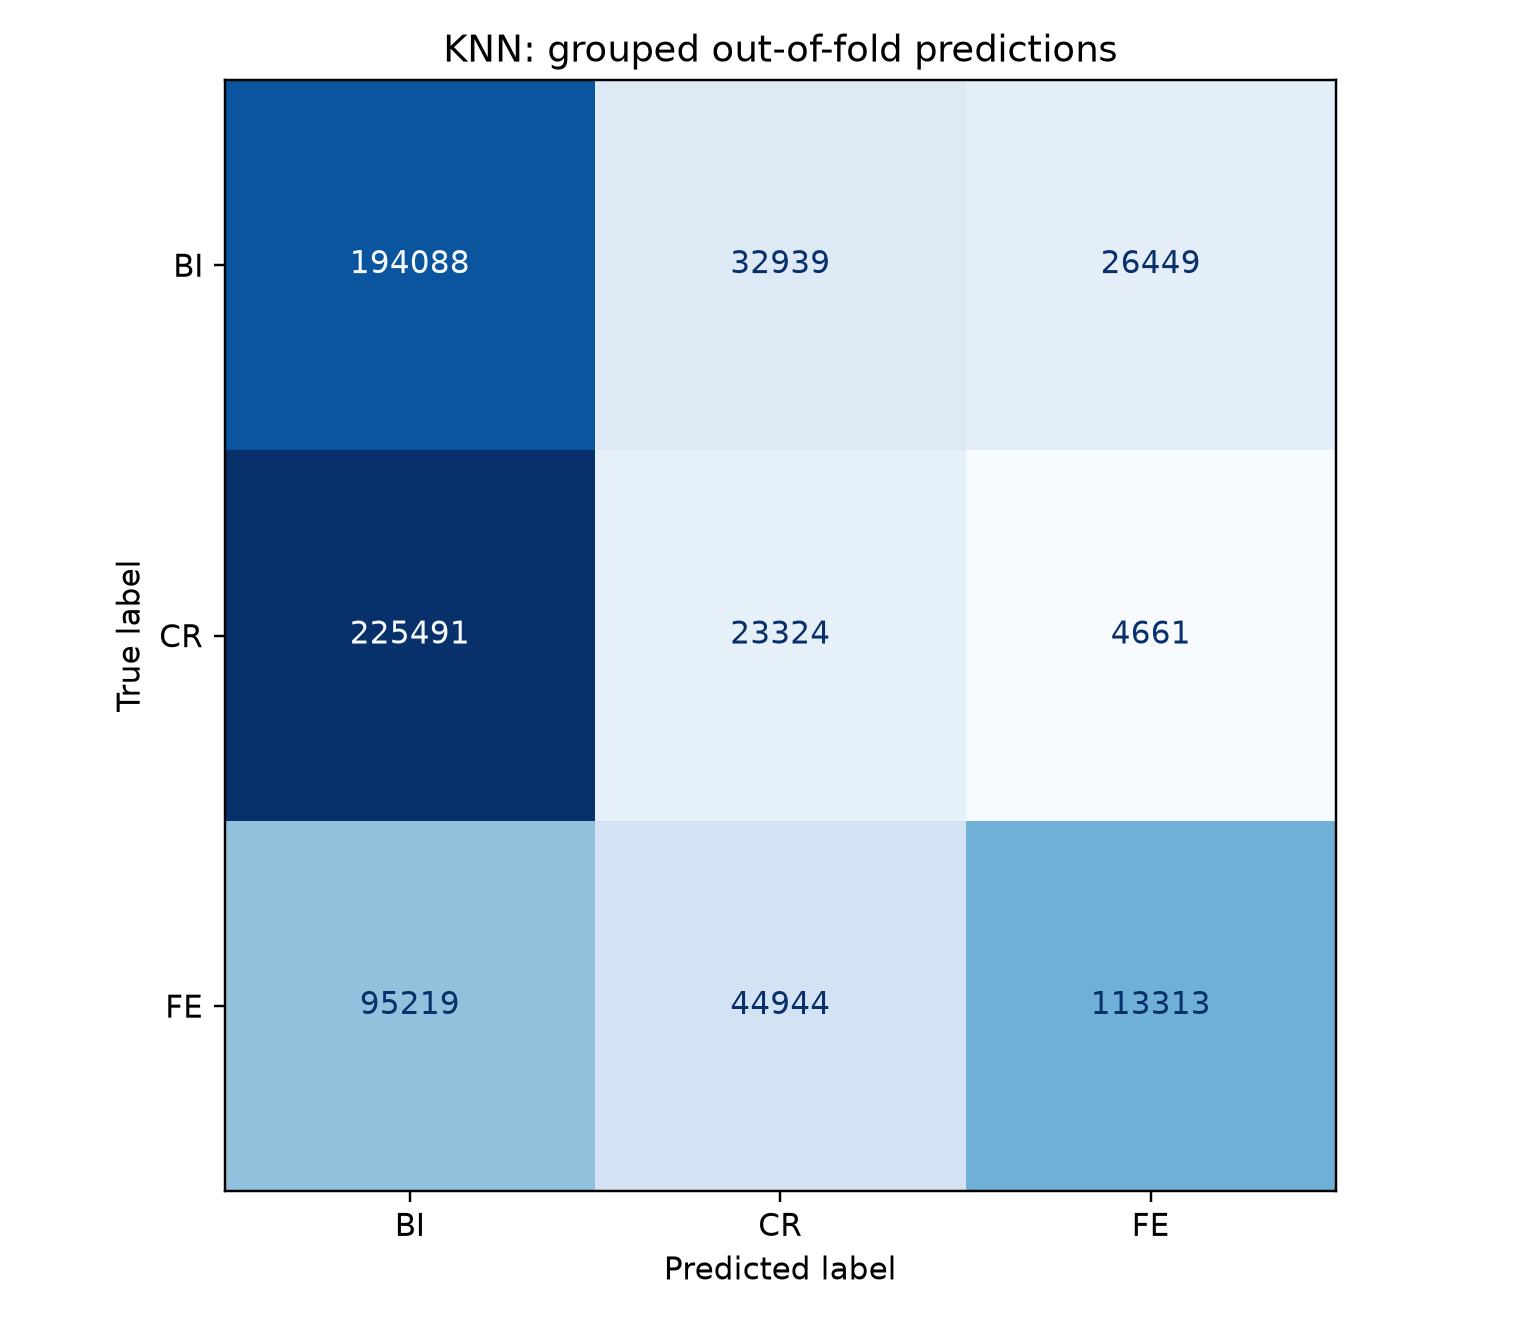

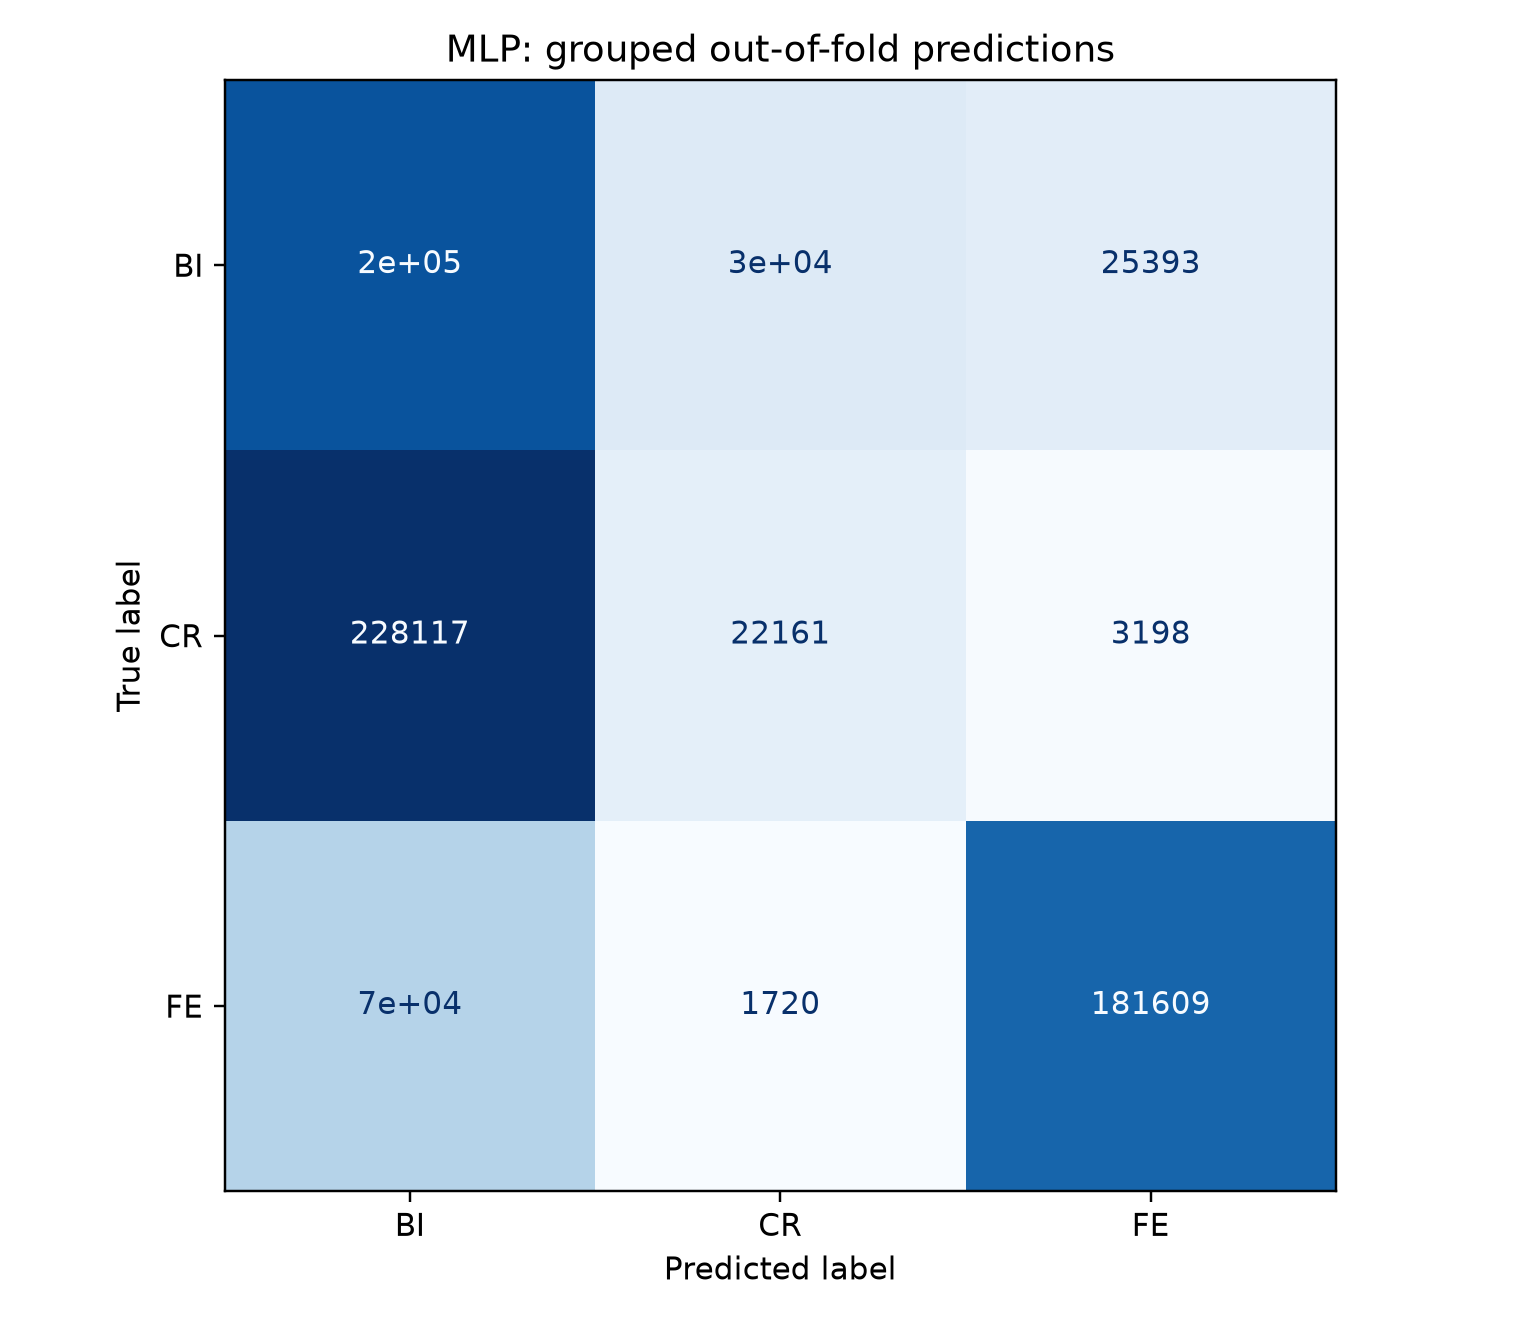

In [4]:
metrics, oof_predictions = evaluate_models(df_train)
display(metrics)
display(pd.read_csv(METRICS_DIR / "evaluation_splits.csv"))
for name in ("knn", "mlp"):
    display(Image(filename=str(FIGURES_DIR / f"{name}_confusion_matrix.png")))

## Exploratory clustering

Cluster numbers are not material labels. The silhouette score is computed on the training (baseline) data, and on a subsample for large datasets.

Silhouette: 0.5560124191510925


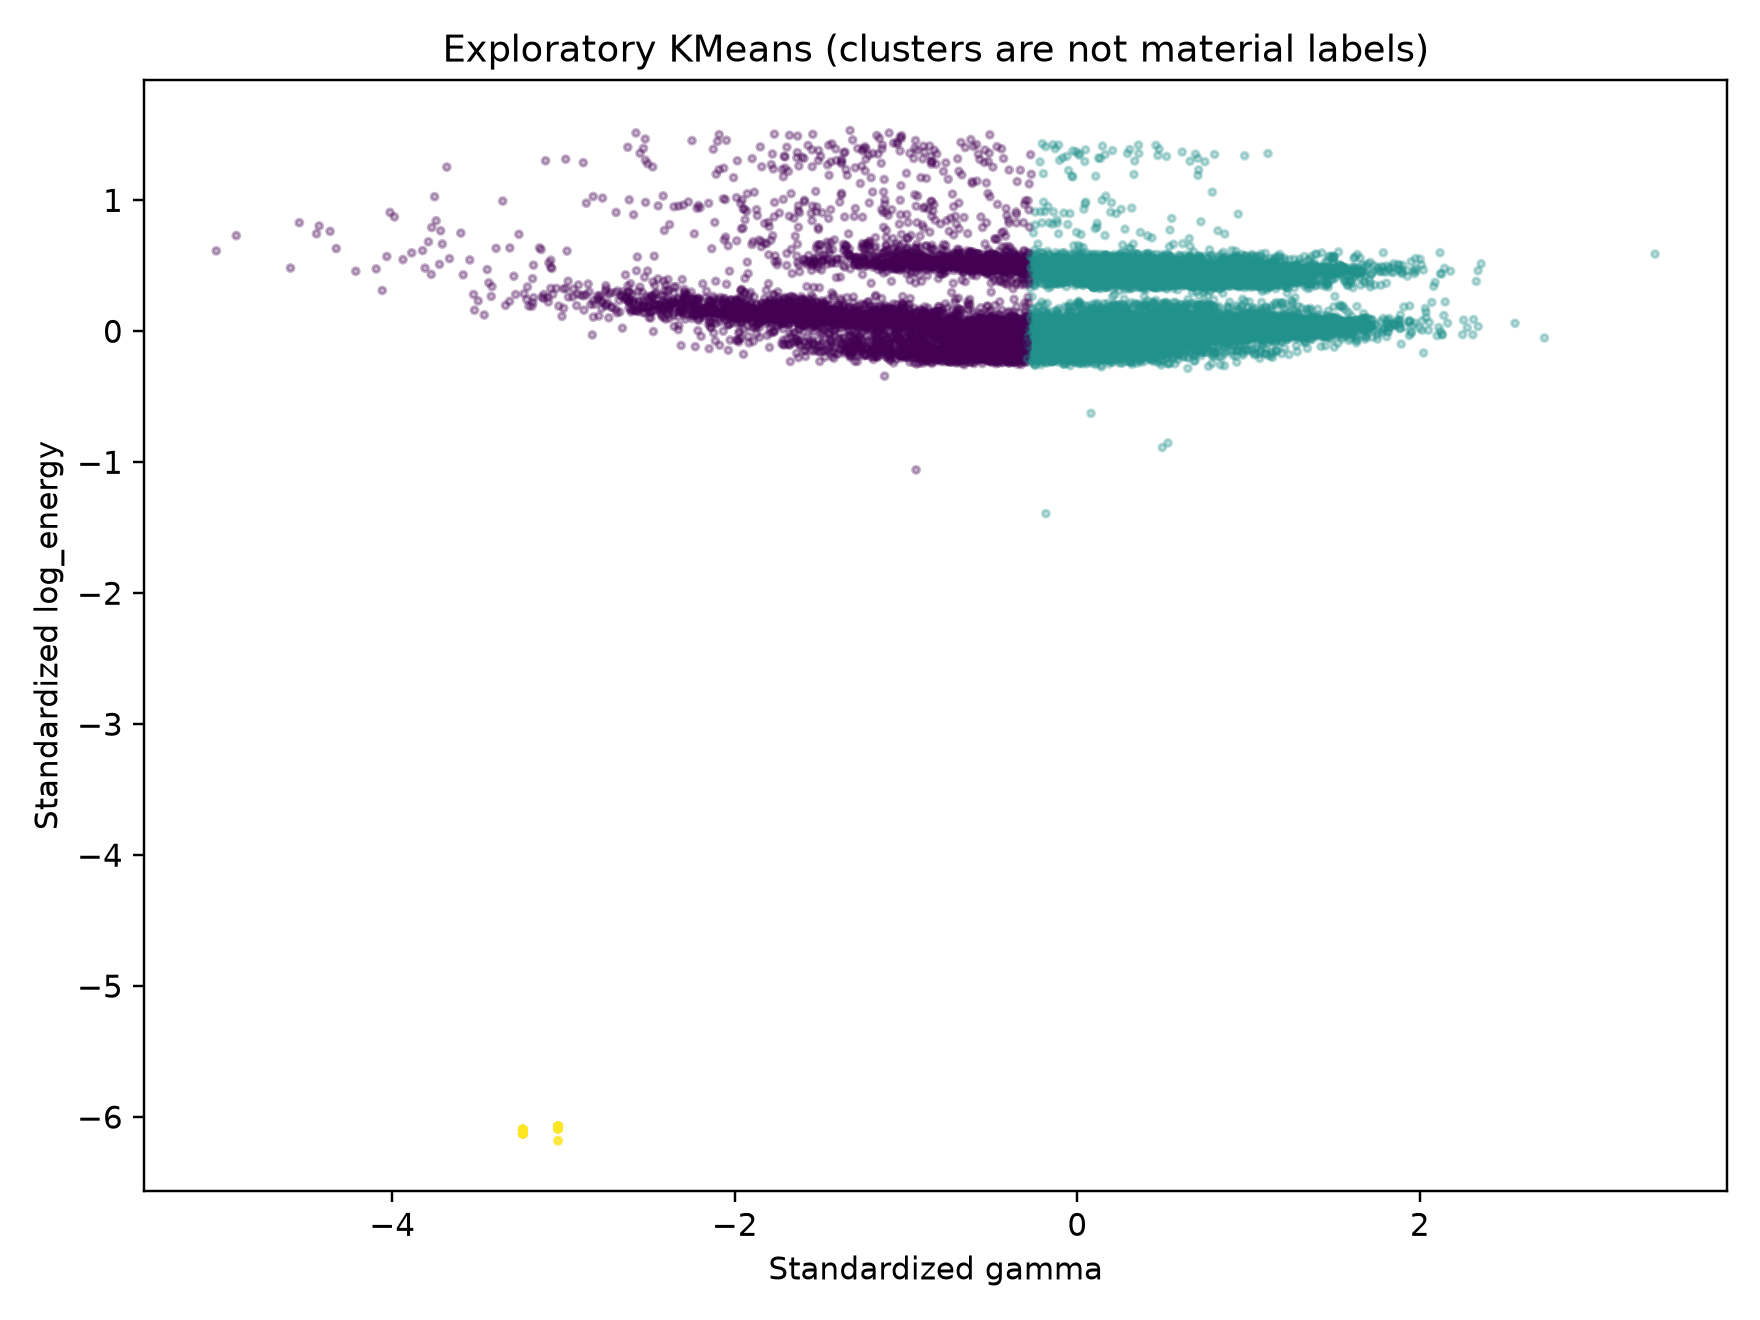

In [5]:
silhouette = analyze_clusters(df_train)
print("Silhouette:", silhouette)
display(Image(filename=str(FIGURES_DIR / "kmeans_clusters.png")))

## Final model and comparison series

The final model is retrained on all baseline series allowed for training. This is not an additional independent estimate of accuracy. A high class probability does not show that a film is stable or that irradiation had no effect.

In [6]:
final_model = fit_final_model(df_train)
comparison_predictions, comparison_summary = analyze_comparison_films(df, final_model)
display(comparison_summary)


Comparison files (one row per file; irradiation may be unknown):
    file experiment_id material channel analysis_role  n_samples  gamma_mean  gamma_std  log_energy_mean  log_energy_std predicted_material  majority_fraction  source_label_fraction  mean_prediction_confidence  prediction_agreement
BI105C01         BI105       BI     C01    comparison      66900     -0.5683     0.3901          -8.6999          0.3099                 BI             0.8154                 0.8154                      0.7123                  True
BI105C02         BI105       BI     C02    comparison      66900     -0.6923     0.5340         -12.1086          8.4755                 BI             0.9480                 0.9480                      0.7191                  True
BI106C01         BI106       BI     C01    comparison     143237     -0.2414     0.2686          -8.6951          0.1931                 BI             0.7239                 0.7239                      0.6695                  True
BI106C

,file,experiment_id,material,channel,analysis_role,n_samples,gamma_mean,gamma_std,log_energy_mean,log_energy_std,predicted_material,majority_fraction,source_label_fraction,mean_prediction_confidence,prediction_agreement
0,BI105C01,BI105,BI,C01,comparison,66900,-0.568314,0.390099,-8.699880,0.309932,BI,0.815366,0.815366,0.712272,True
1,BI105C02,BI105,BI,C02,comparison,66900,-0.692336,0.534009,-12.108584,8.475529,BI,0.948042,0.948042,0.719121,True
2,BI106C01,BI106,BI,C01,comparison,143237,-0.241357,0.268624,-8.695099,0.193138,BI,0.723940,0.723940,0.669479,True
3,BI106C02,BI106,BI,C02,comparison,143237,-0.366708,0.267364,-8.950260,0.156747,BI,0.946662,0.946662,0.685143,True
4,CR205C01,CR205,CR,C01,comparison,66900,-1.343322,0.416104,-12.678567,9.826284,CR,0.911121,0.911121,0.823267,True
5,CR205C02,CR205,CR,C02,comparison,66900,-1.614374,0.441017,-23.148290,13.409711,BI,0.606756,0.353423,0.839280,False
6,CR206C01,CR206,CR,C01,comparison,143237,-1.152569,0.322257,-8.313706,1.298358,CR,0.829611,0.829611,0.834388,True
7,CR206C02,CR206,CR,C02,comparison,143237,-1.257296,0.400625,-12.621669,9.699870,CR,0.656925,0.656925,0.841415,True
8,FE105C01,FE105,FE,C01,comparison,66900,-0.032205,0.252100,-6.834570,0.183833,FE,0.999581,0.999581,0.991863,True
9,FE105C02,FE105,FE,C02,comparison,66900,-0.054057,0.260192,-7.158791,0.115792,FE,0.998012,0.998012,0.976338,True


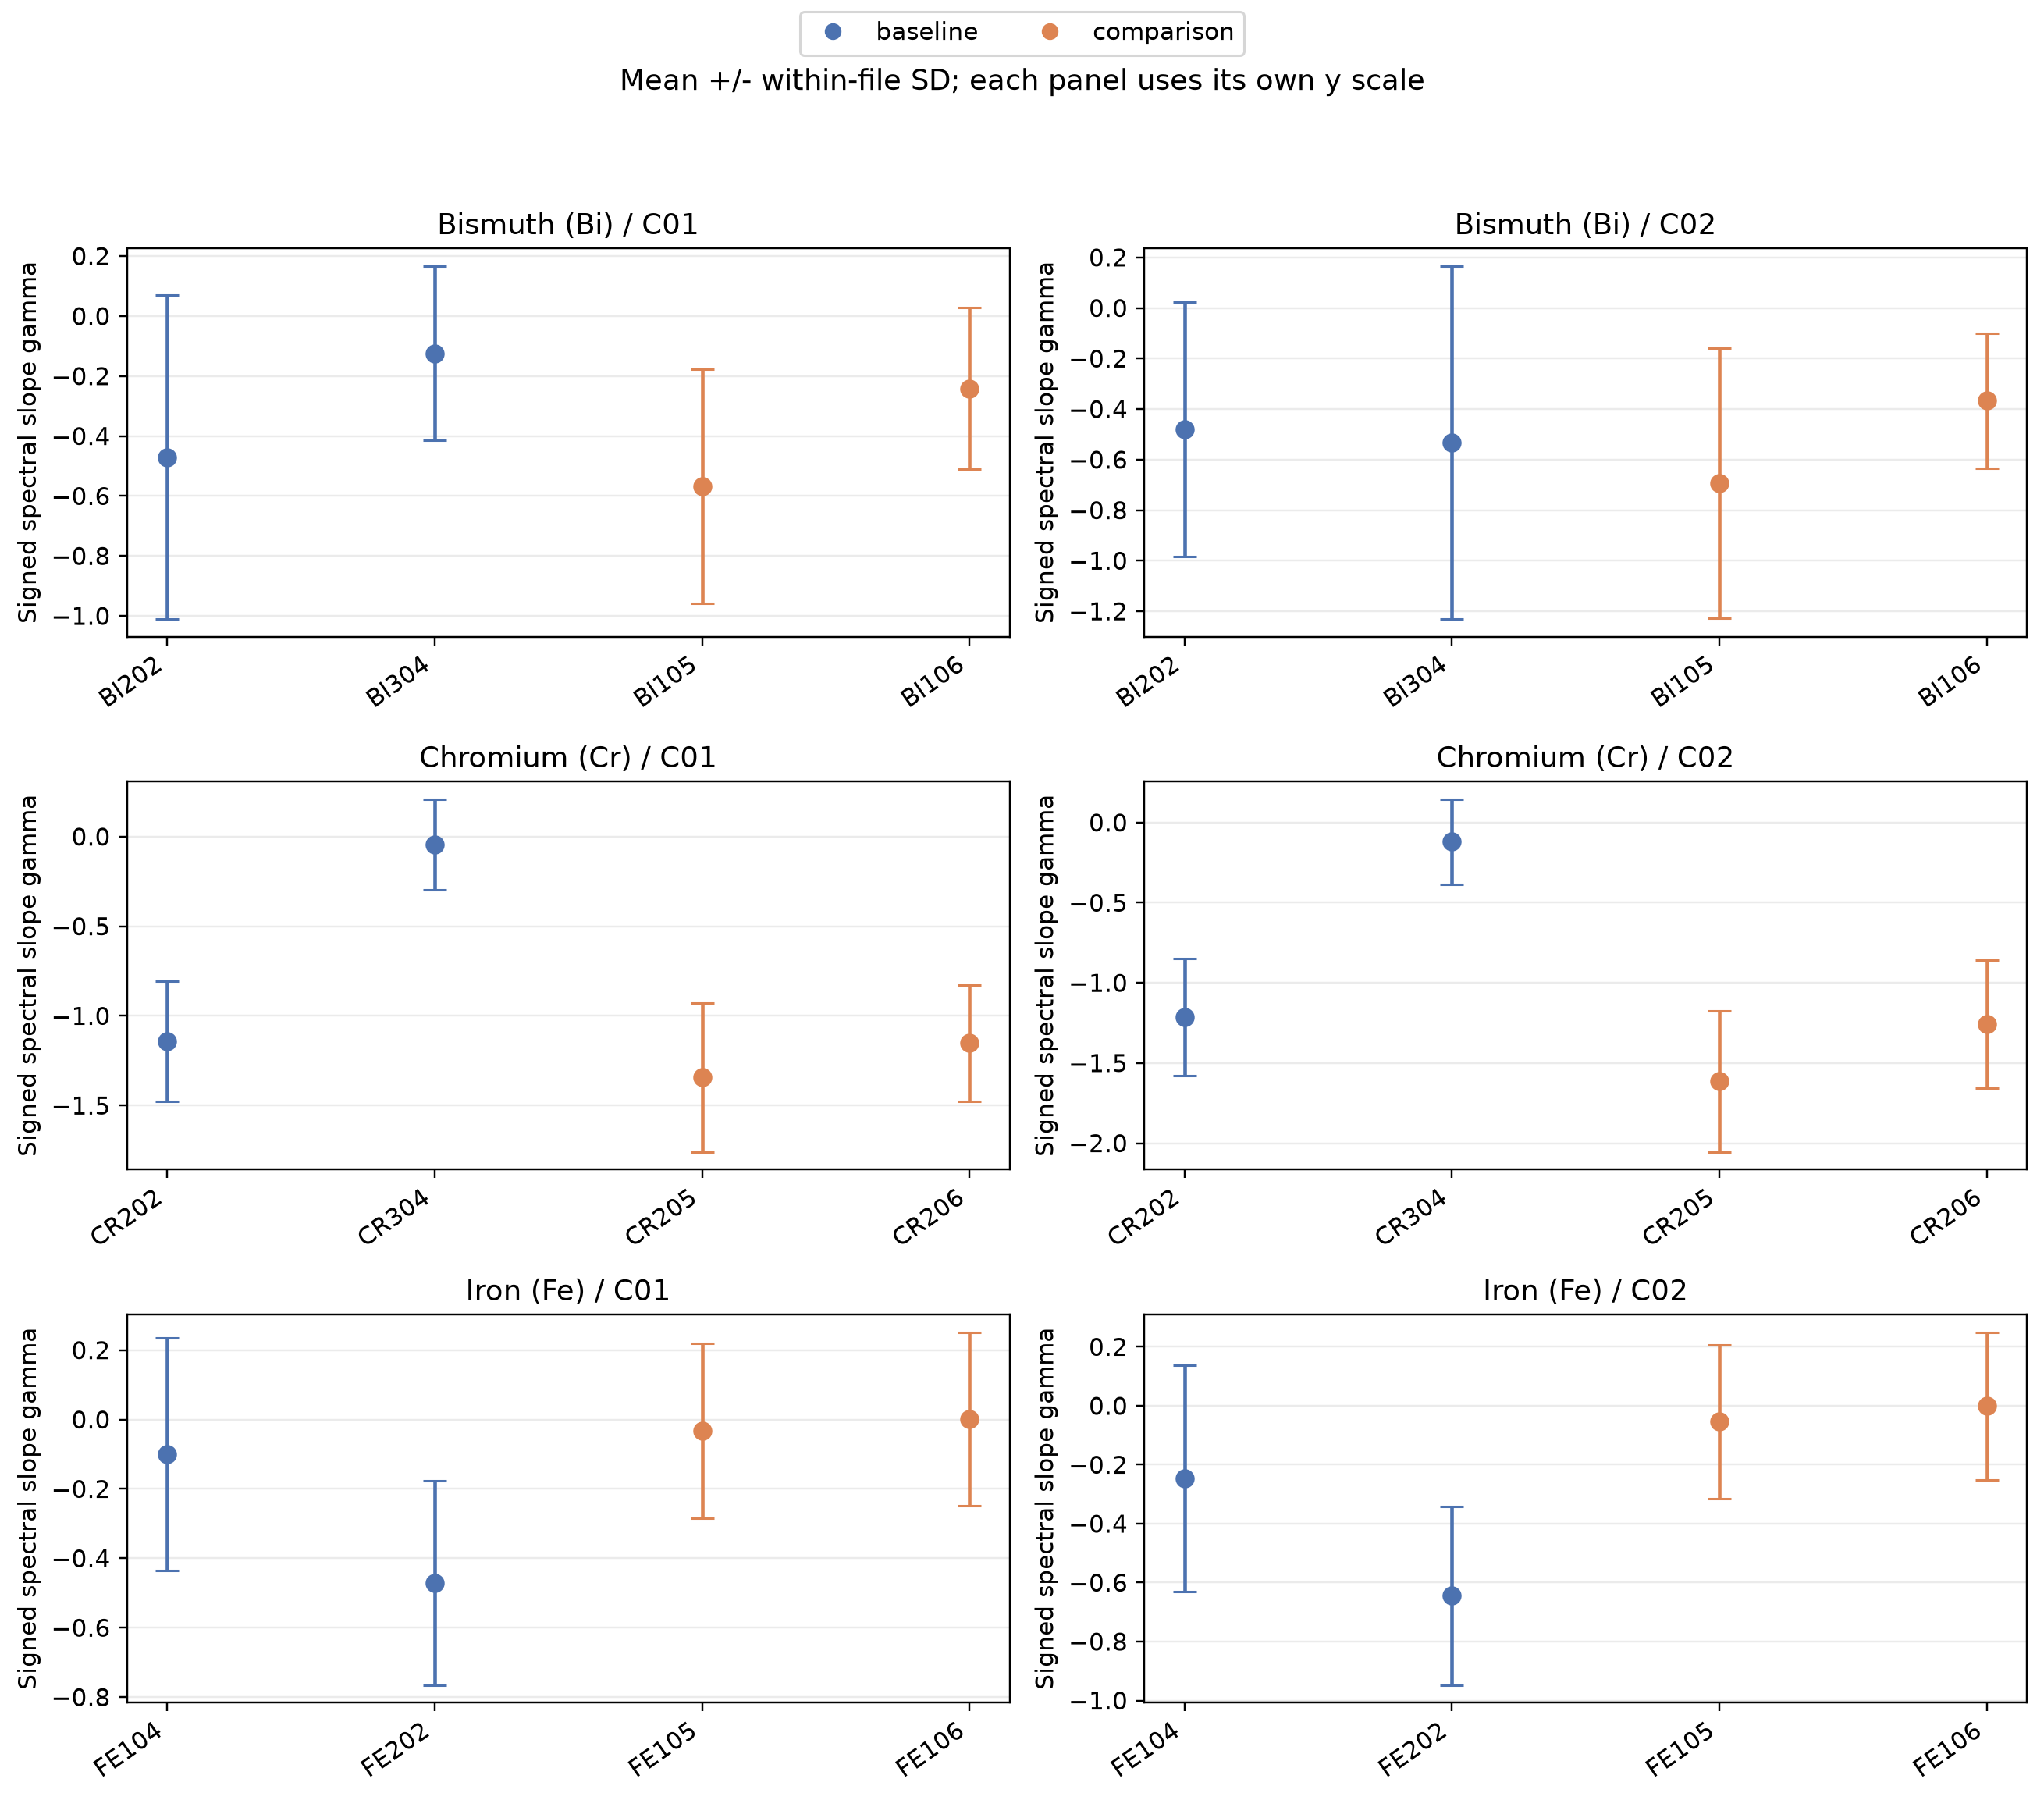

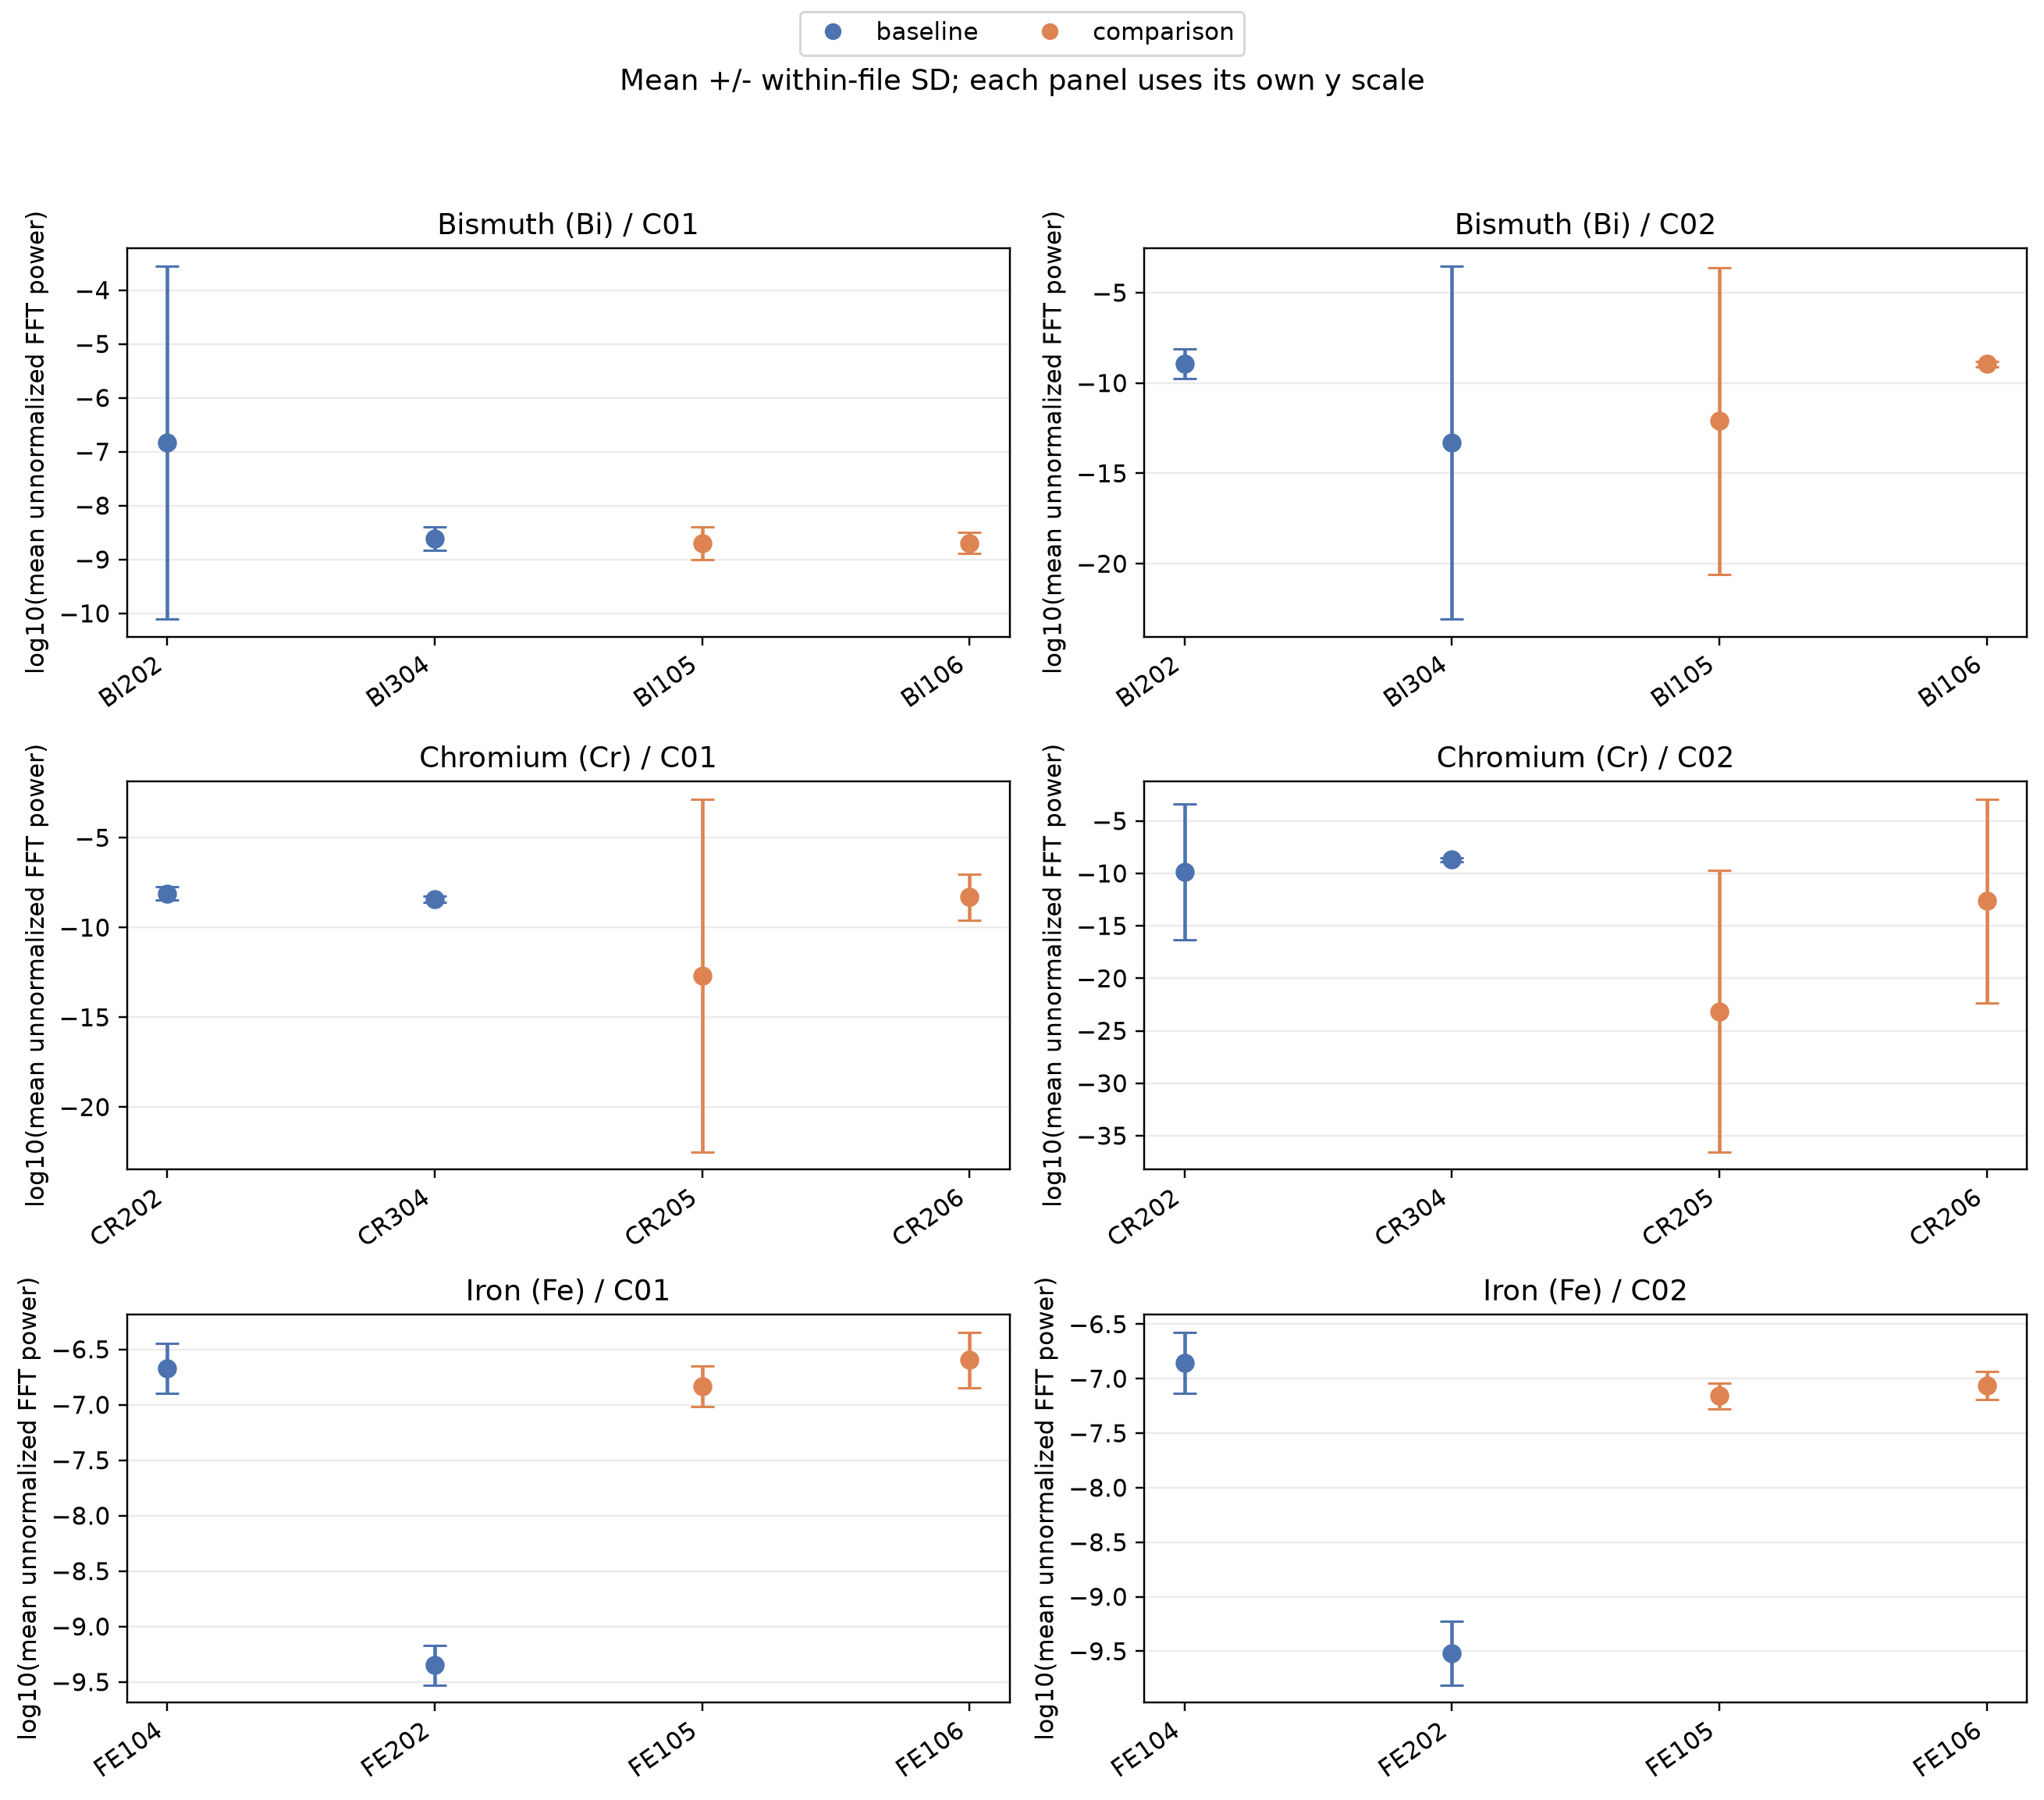

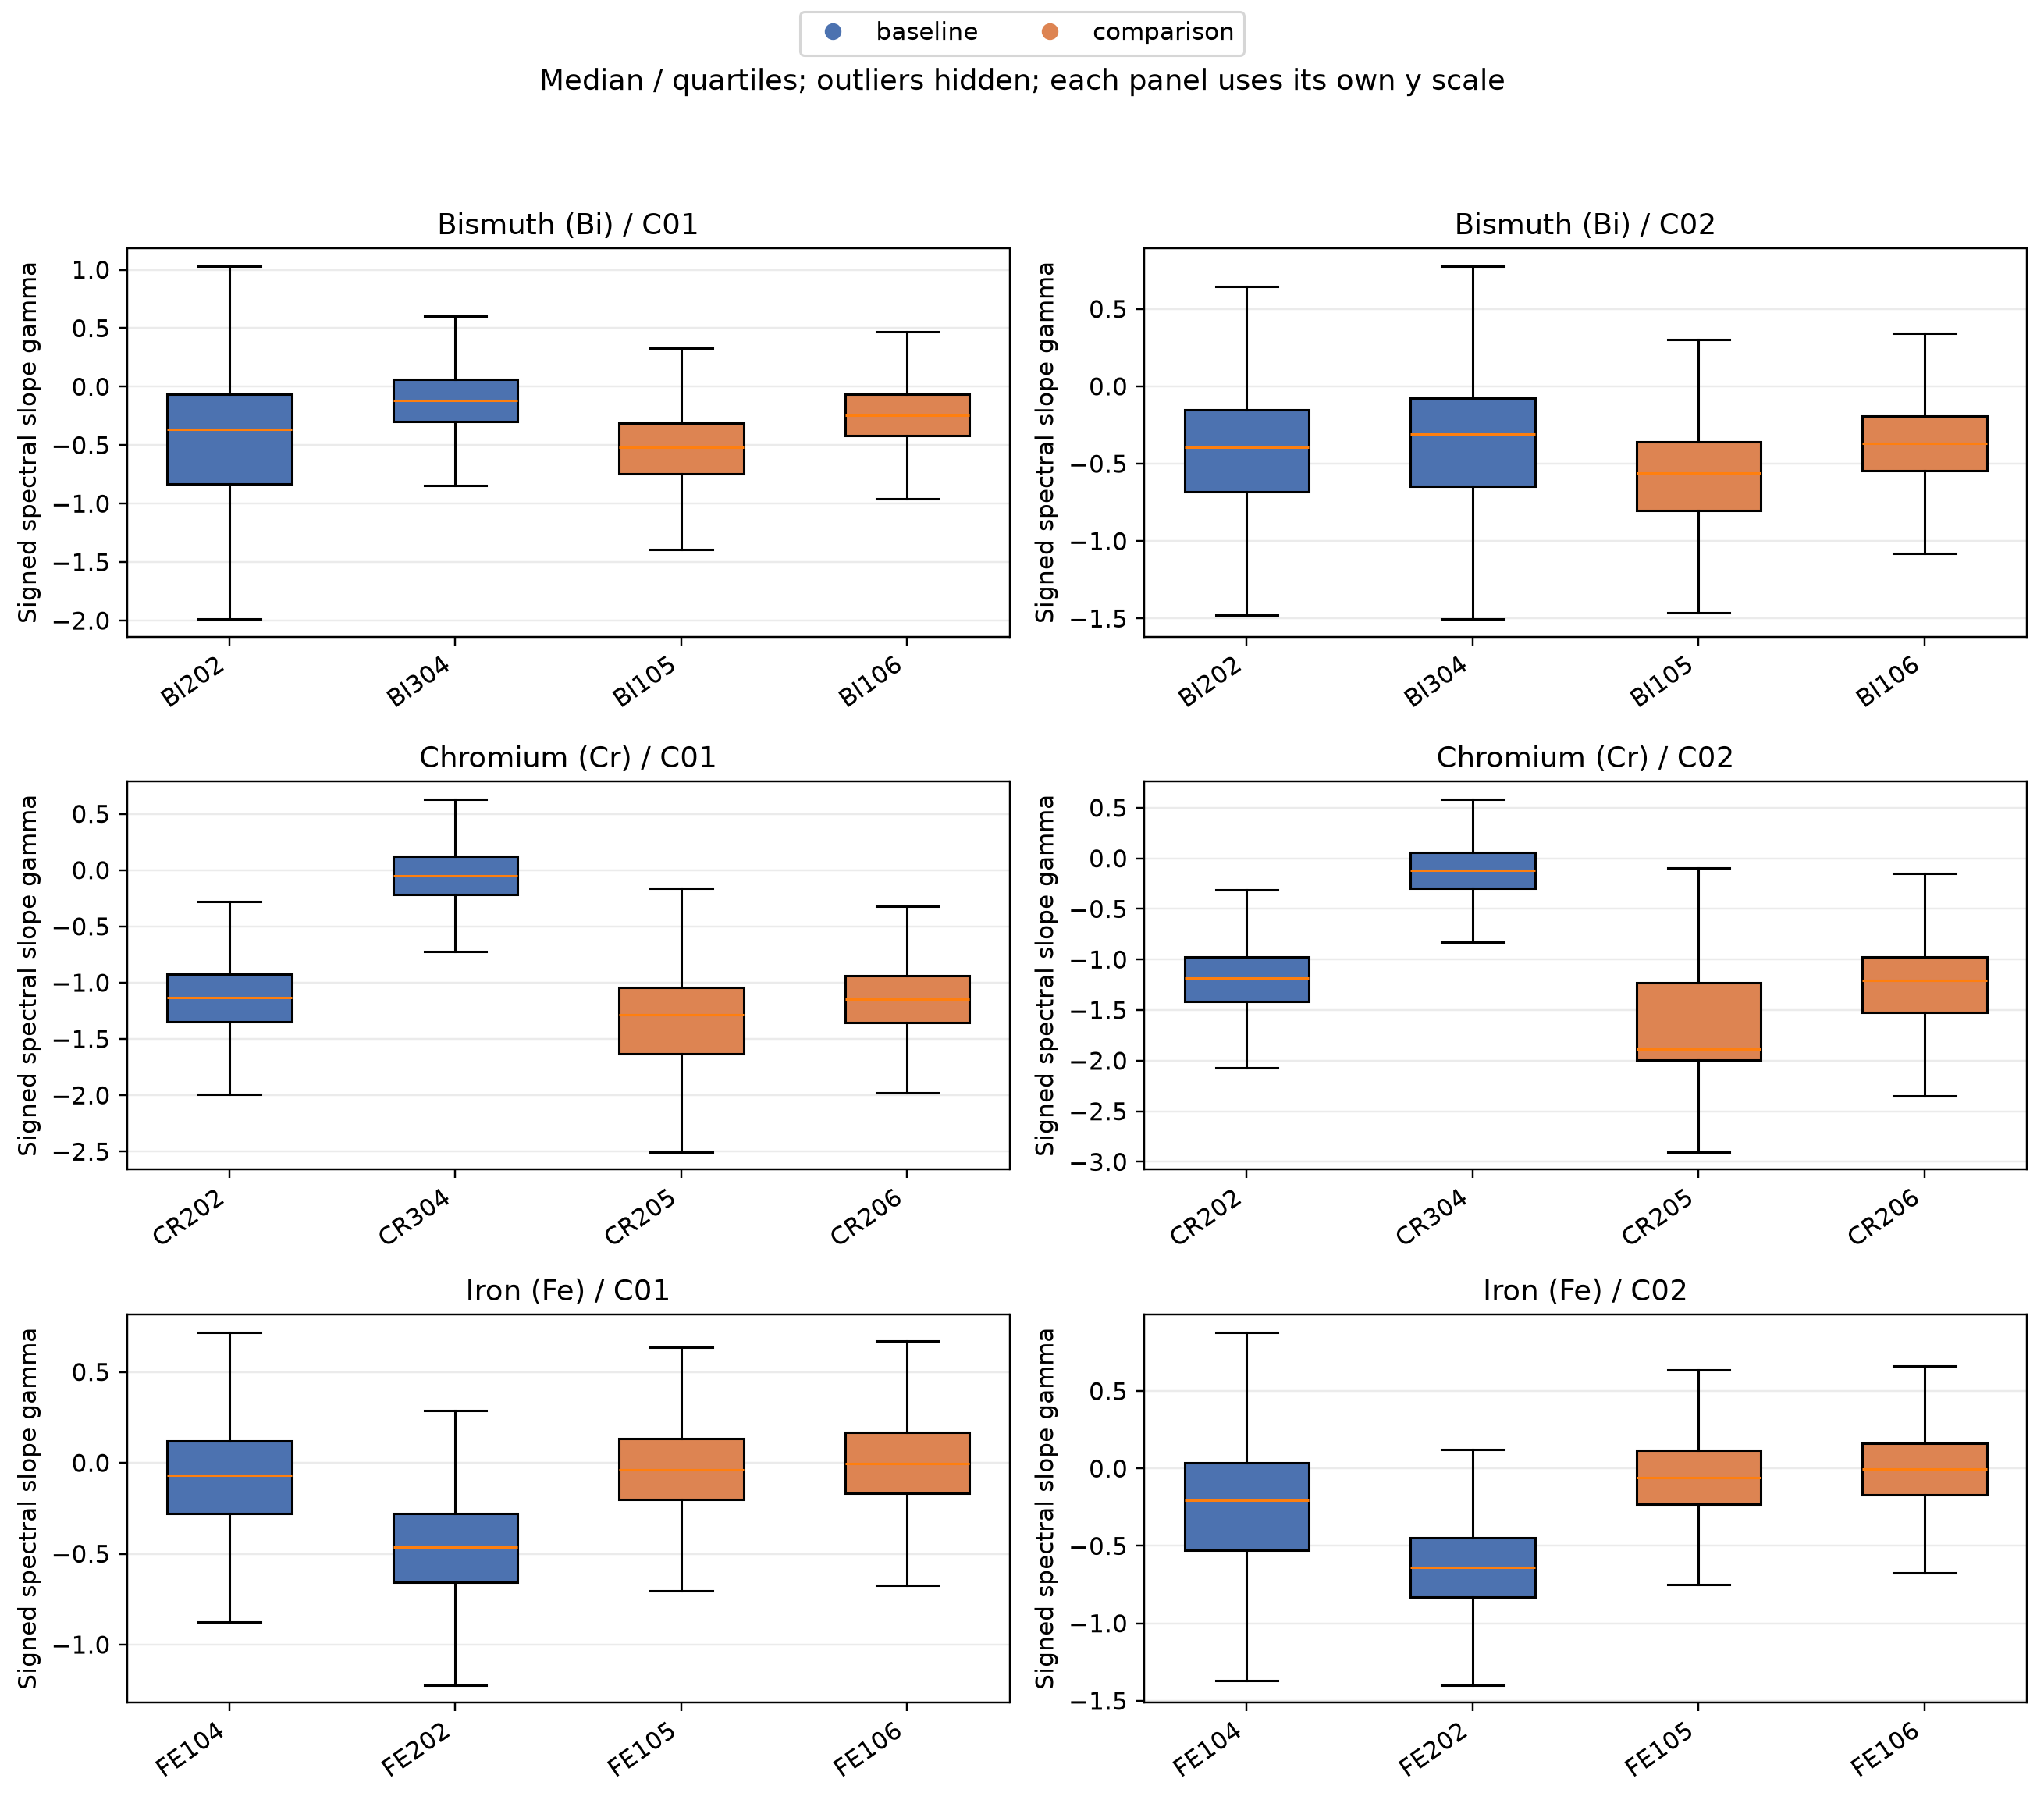

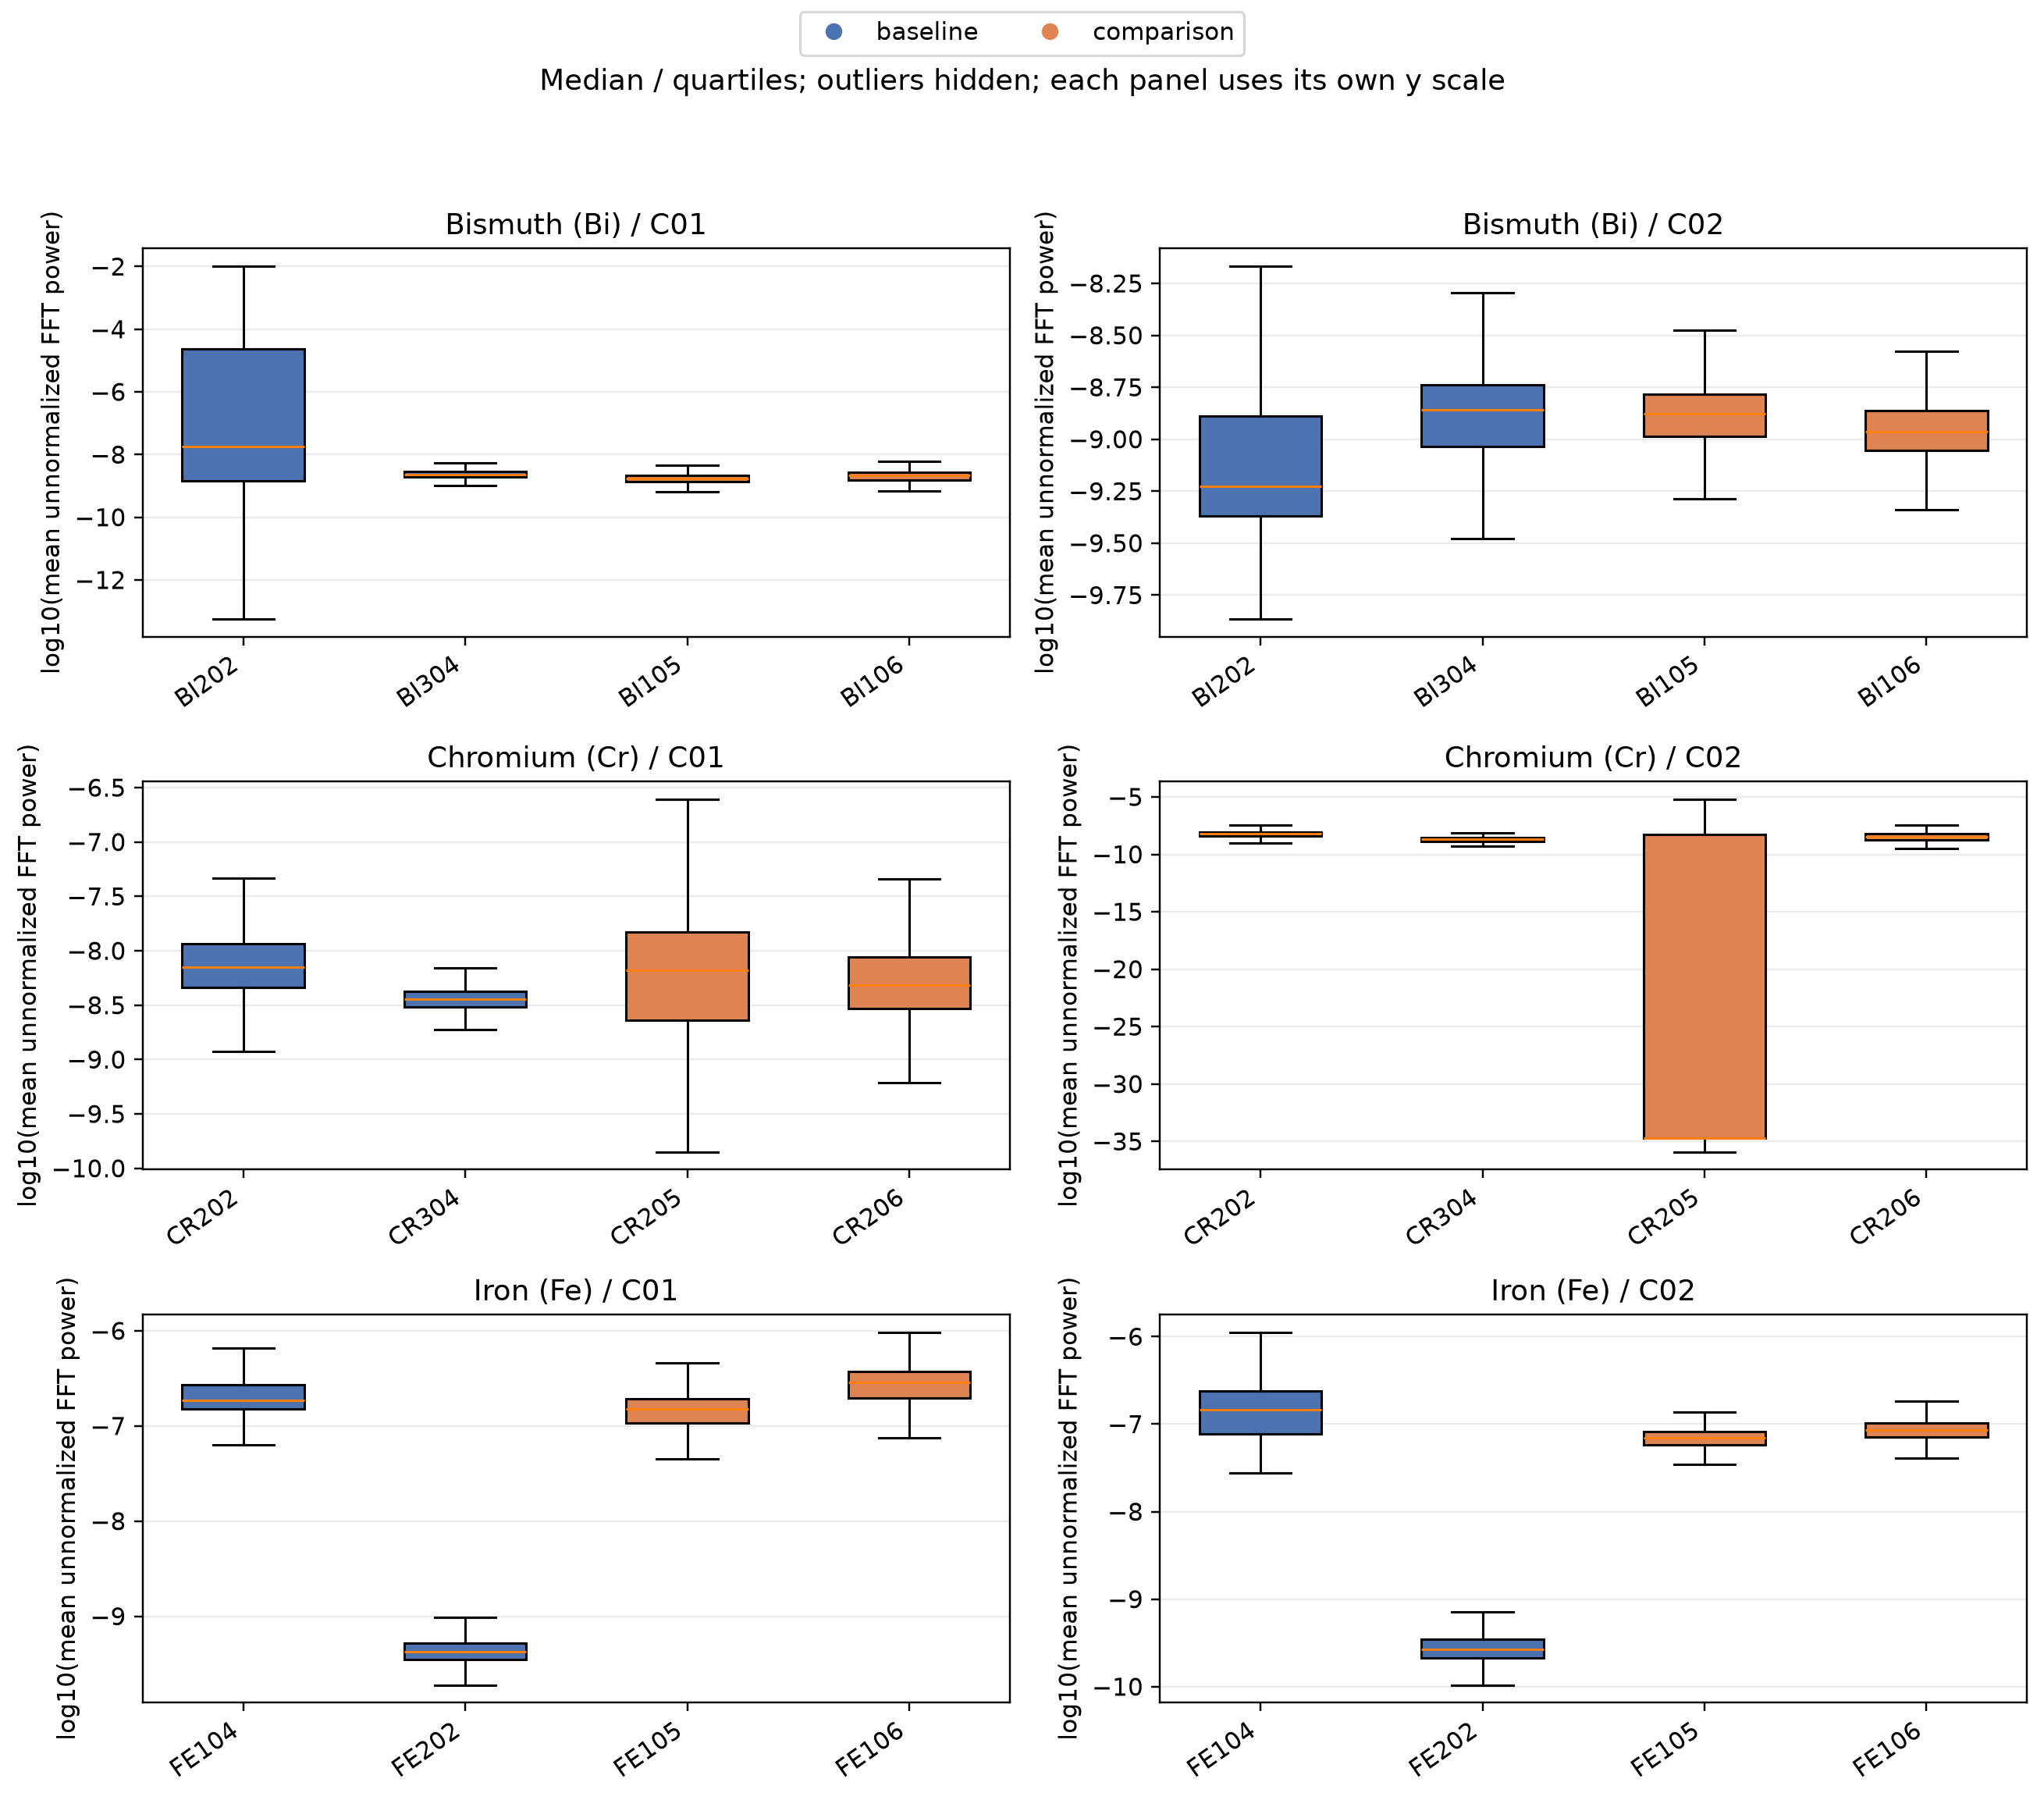

In [7]:
save_feature_plots(df)
for filename in ("file_level_gamma_comparison.png", "file_level_energy_comparison.png",
                 "gamma_boxplots_by_file.png", "energy_boxplots_by_file.png"):
    display(Image(filename=str(FIGURES_DIR / filename)))

## Results

Full predictions are in `comparison_film_predictions.csv`, and a per-file summary is in `comparison_file_summary.csv`. `irradiated_film_predictions.csv` contains only rows with confirmed `irradiated=True`; while the status is unknown, it is empty apart from the header. Running this notebook overwrites the files in `results/metrics` and the figures in `results/figures`. Older images that are no longer produced are not deleted.